In [1]:
# %load_ext watermark # this is so that in the end we can check which module versions we used
%load_ext autoreload

import warnings 
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import xarray
import xesmf
from pathlib import Path
from regional_mom6 import regridding as rgd

In [12]:
import xarray as xr
import numpy as np
rof = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/runoff/glofas_runoff/GloFAS_little_nwa.nc")
rof["runoff"] = rof["runoff"].where(rof["runoff"]>=0,0)
rof.to_netcdf("/glade/u/home/manishrv/documents/croc/dev/runoff/glofas_runoff/GloFAS_little_nwa.nc")


In [20]:
# Create simple grid modification for domain file
import xarray as xr
hgrid = xr.open_dataset("/glade/u/home/manishrv/croc_input/rt.1.ln/ocnice/ocean_hgrid_little_nwa12_fee72b.nc")
topo = xr.open_dataset("/glade/u/home/manishrv/croc_input/rt.1.ln/ocnice/ocean_topog_little_nwa12_fee72b.nc")
ds = xr.Dataset()
hgrid["qlon"] = (("nyq","nxq"),rgd.get_hgrid_arakawa_c_points(hgrid,point_type ="q").qlon.values)
hgrid["qlat"] = (("nyq","nxq"),rgd.get_hgrid_arakawa_c_points(hgrid,point_type ="q").qlat.values)
hgrid["tlon"] = (("nyt","nxt"),rgd.get_hgrid_arakawa_c_points(hgrid,point_type ="t").tlon.values)
hgrid["tlat"] = (("nyt","nxt"),rgd.get_hgrid_arakawa_c_points(hgrid,point_type ="t").tlat.values)

hgrid["tmask"] = (("nyt","nxt"),topo.mask.values)
hgrid = hgrid.drop_dims(["nyp","nxp","nx","ny"])
hgrid.to_netcdf("/glade/u/home/manishrv/documents/croc/dev/runoff/ncl_required_fields_hgrid.nc")

In [2]:
def wrapper_deg2rad(lat):
    return np.deg2rad(lat)

def wrapper_cos(val):
    return np.cos(val)

In [3]:
def get_coast_mask(mask_file):
    mask = xarray.open_dataset(mask_file)
    
    # Alistair's method of finding coastal cells
    ocn_mask = mask.mask.values
    cst_mask = 0 * ocn_mask # All land should be 0
    is_ocean = ocn_mask > 0
    cst_mask[(is_ocean) & (np.roll(ocn_mask, 1, axis=1) == 0)] = 1 # Land to the west
    cst_mask[(is_ocean) & (np.roll(ocn_mask, -1, axis=1) == 0)] = 1 # Land to the east
    cst_mask[(is_ocean) & (np.roll(ocn_mask, 1, axis=0) == 0)] = 1 # Land to the south
    cst_mask[(is_ocean) & (np.roll(ocn_mask, -1, axis=0) == 0)] = 1 # Land to the north

    # Model boundaries are not coasts
    cst_mask[0, :] = 0
    cst_mask[:, 0] = 0
    cst_mask[-1, :] = 0
    cst_mask[:, -1] = 0

    return cst_mask

In [56]:
def write_runoff(glofas, glofas_mask, hgrid, coast_mask, out_file):
    glofas_latb = np.arange(glofas['latitude'][0]+.05, glofas['latitude'][-1]-.051, -.1)
    glofas_lonb = np.arange(glofas['longitude'][0]-.05, glofas['longitude'][-1]+.051, .1)
    
    lon = hgrid.x[1::2, 1::2]
    lonb = hgrid.x[::2, ::2]
    lat = hgrid.y[1::2, 1::2]
    latb = hgrid.y[::2, ::2]
    # From Alistair
    area = (hgrid.area[::2, ::2] + hgrid.area[1::2, 1::2]) + (hgrid.area[1::2, ::2] + hgrid.area[::2, 1::2])
    
    # Convert m3/s to kg/m2/s
    # Borrowed from https://xgcm.readthedocs.io/en/latest/xgcm-examples/05_autogenerate.html
    distance_1deg_equator = 111000.0
    dlon = dlat = 0.1  # GloFAS grid spacing
    deg2rad = xarray.apply_ufunc(wrapper_deg2rad, glofas.latitude)
    cos = xarray.apply_ufunc(wrapper_cos, deg2rad)
    dx = dlon * cos * distance_1deg_equator
    dy = ((glofas.longitude * 0) + 1) * dlat * distance_1deg_equator
    glofas_area = dx * dy
    glofas_rof = glofas * 1000.0 / glofas_area
    
    # Conservatively interpolate runoff onto MOM grid
    glofas_to_mom_con = xesmf.Regridder(
        {'lon': glofas.longitude, 'lat': glofas.latitude, 'lon_b': glofas_lonb, 'lat_b': glofas_latb},
        {'lat': lat, 'lon': lon, 'lat_b': latb, 'lon_b': lonb},
        method='bilinear',
        periodic=True,
        reuse_weights=False
    )
    # Interpolate only from GloFAS points that are river end points.
    glofas_regridded = glofas_to_mom_con(glofas_rof.where(glofas_mask > 0).fillna(0.0))
    
    glofas_regridded = glofas_regridded.rename({'nyp': 'ny', 'nxp': 'nx'}).values

    # For NWA only: remove runoff from west coast of Guatemala 
    # and El Salvador that actually drains into the Pacific.
    #glofas_regridded[:, 0:125, 0:30] = 0.0
    
    # For NWA only: remove runoff from Newfoundland 
    # and Labrador that actually drains outside of the model domain.
   # glofas_regridded[:, 680:720, 340:360] = 0.0

    # Flatten mask and coordinates to 1D
    flat_mask = coast_mask.ravel().astype('bool')
    coast_lon = lon.values.ravel()[flat_mask]
    coast_lat = lat.values.ravel()[flat_mask]
    mom_id = np.arange(np.prod(coast_mask.shape))

    # Use xesmf to find the index of the nearest coastal cell
    # for every grid cell in the MOM domain
    coast_to_mom = xesmf.Regridder(
        {'lat': coast_lat, 'lon': coast_lon},
        {'lat': lat, 'lon': lon},
        method='nearest_s2d',
        locstream_in=True,
        reuse_weights=False
    )
    print("finished coast 2 mom regridding")
    coast_id = mom_id[flat_mask]
    nearest_coast = coast_to_mom(coast_id).ravel()

    # Raw runoff on MOM grid, reshaped to 2D (time, grid_id)
    raw = glofas_regridded.reshape([glofas_regridded.shape[0], -1])

    # Zero array that will be filled with runoff at coastal cells
    filled = np.zeros_like(raw)

    # Loop over each coastal cell and fill the result array
    # with the sum of runoff for every grid cell that
    # has this coastal cell as its closest coastal cell
    for i in coast_id:
        filled[:, i] = raw[:, nearest_coast == i].sum(axis=1)

    # Reshape back to 3D
    filled_reshape = filled.reshape(glofas_regridded.shape)

    # For NWA only: Mississippi River adjustment.
    # Adjust to be approximately the same as the USGS station at Belle Chasse, LA
    # and relocate closer to the end of the delta.
    #ms_total_kg = filled_reshape[:, 285:295, 189:197] 
    #ms_total = (ms_total_kg * np.broadcast_to(area[285:295, 189:197], ms_total_kg.shape)).sum(axis=(1, 2)) * 0.63 
    #filled_reshape[:, 285:295, 189:197] = 0.0
    #new_ms_coords = [(285, 188), (282, 191), (284, 195)]
    #for c in new_ms_coords:
        #y, x = c
        #filled_reshape[:, y, x] = (1 / len(new_ms_coords)) * ms_total / float(area[y, x])
    
    # For NWA only: add the lower Atchafalaya River based on 
    # a linear regression using Belle Chasse, LA. 
    # 1. Convert back to m3 / s
    #ms_total_cms = ms_total / 1000.0
    # 2. Estimate from regression. 
    #estimate = 0.25398171869266334 * ms_total_cms - 321.07060528972397
    # Keep the estimate >= 0.
    #estimate = np.clip(estimate, 0, None)
    # 3. Convert back to kg / m2 / s
    #estimate_kg = estimate * 1000.0 / float(area[310, 177])
    # 4. Add in place of existing Atchafalaya River in GloFAS. 
    #filled_reshape[:, 310, 177] += estimate_kg

    # Convert to xarray
    ds = xarray.Dataset({
        'runoff': (['time', 'y', 'x'], filled_reshape),
        'area': (['y', 'x'], area.data),
        'lat': (['y', 'x'], lat.data),
        'lon': (['y', 'x'], lon.data)
        },
        coords={'time': glofas['time'].data, 'y': np.arange(filled_reshape.shape[1]),
                'x': np.arange(filled_reshape.shape[2])}
    )

    # Drop '_FillValue' from all variables when writing out
    all_vars = list(ds.data_vars.keys()) + list(ds.coords.keys())
    encodings = {v: {'_FillValue': None} for v in all_vars}

    # Make sure time has the right units and datatype
    # otherwise it will become an int and MOM will fail. 
    encodings['time'].update({
        'units': 'days since 1950-01-01',
        'dtype': np.float, 
        'calendar': 'gregorian'
    })

    ds['time'].attrs = {'cartesian_axis': 'T'}
    ds['x'].attrs = {'cartesian_axis': 'X'}
    ds['y'].attrs = {'cartesian_axis': 'Y'}
    ds['lat'].attrs = {'units': 'degrees_north'}
    ds['lon'].attrs = {'units': 'degrees_east'}
    ds['runoff'].attrs = {'units': 'kg m-2 s-1'}
    
    print(ds)
    # Write out
    ds.to_netcdf(
        out_file,
        unlimited_dims=['time'],
        format='NETCDF3_64BIT',
        encoding=encodings,
        engine='netcdf4'
    )
    ds.close()

In [7]:
mom_grid

<xarray.Dataset>
Dimensions:         (elementCount: 754, coordDim: 2, nodeCount: 810,
                     maxNodePElement: 4)
Dimensions without coordinates: elementCount, coordDim, nodeCount,
                                maxNodePElement
Data variables:
    centerCoords    (elementCount, coordDim) float64 ...
    numElementConn  (elementCount) int8 ...
    elementArea     (elementCount) float64 ...
    elementMask     (elementCount) int32 ...
    nodeCoords      (nodeCount, coordDim) float64 ...
    elementConn     (elementCount, maxNodePElement) int32 ...
Attributes:
    gridType:      unstructured mesh
    date_created:  2025-01-28T16:24:18.266794

In [ ]:
import xarray as xr
coast_mask = get_coast_mask('/glade/u/home/manishrv/croc_input/rt.1.ln/ocnice/ocean_topog_little_nwa12_fee72b.nc')
hgrid = xarray.open_dataset( '/glade/u/home/manishrv/croc_input/rt.1.ln/ocnice/ocean_hgrid_little_nwa12_fee72b.nc')
mom_grid = xarray.open_dataset('/glade/u/home/manishrv/croc_input/rt.1.ln/ocnice/ESMF_mesh_little_nwa12_fee72b.nc')

uparea = xarray.open_dataarray('/glade/work/gmarques/Projects/CROCODILE/GloFAS/upArea.nc')#.sel(**glofas_subset)
uparea = uparea.fillna(0).values
points = np.zeros_like(uparea)
out_file = Path("/glade/u/home/manishrv/documents/croc/dev/runoff/GloFAS")
glodas_runoff_raw = xr.open_dataset("/glade/work/gmarques/Projects/CROCODILE/GloFAS/2000_2020/GloFAS_2000_2020_raw.nc")
out_file = Path("/glade/u/home/manishrv/documents/croc/dev/runoff/GloFAS_little_nwa_2.nc")
write_runoff(glodas_runoff_raw,points,hgrid, coast_mask,out_file = out_file)
lat_min = hgrid.y.min().values
lat_max = hgrid.y.max().values
lon_min = hgrid.x.min().values
lon_max = hgrid.x.max().values


In [9]:
# Subset GloFAS to a smaller region containing grid.It seems subset must be exactly the size of the mom grid
glofas_subset = dict(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))

In [10]:
# GloFAS upstream area from 
# https://confluence.ecmwf.int/download/attachments/143039724/upArea.nc?version=5&modificationDate=1606390153801&api=v2
# The metadata says it is GloFAS version 2.1, but it looks like a good match for 3.1
uparea = xarray.open_dataarray('/glade/work/gmarques/Projects/CROCODILE/GloFAS/upArea.nc')#.sel(**glofas_subset)

In [11]:
# flip latitude and select region
uparea = uparea.isel(lat=slice(None, None, -1)).sel(**glofas_subset)

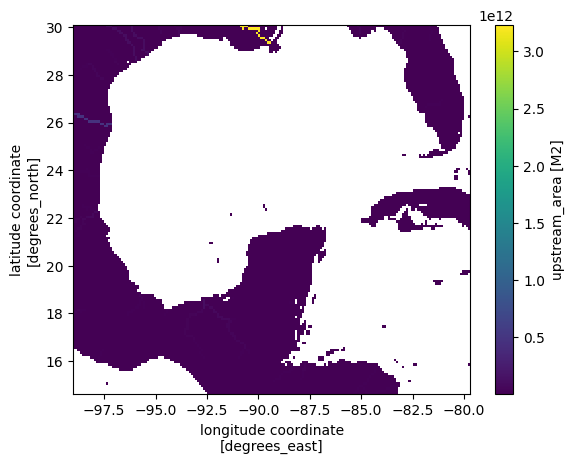

In [12]:
uparea.plot()

In [13]:
# Find river end points by looking for local maxima in upstream area.
uparea = uparea.fillna(0).values
points = np.zeros_like(uparea)
window = 2  # look with +- this number of grid points
ni, nj = uparea.shape
for i in range(window, ni-window):
    for j in range(window, nj-window):
        sub = uparea[i-window:i+window+1, j-window:j+window+1]
        point = uparea[i, j]
        # A river end point has a reasonably large upstream area
        # and is a local maximum
        if point > 1e6 and sub.max() == point:
            points[i, j] = 1


In [14]:
#for y in range(1996, 1997):
#    print(y)
    # GloFAS 3.1 data copied to vftmp from:
    # /archive/e1n/datasets/GloFAS/
files = '/glade/work/gmarques/Projects/CROCODILE/GloFAS/2000_2020/GloFAS_2000_2020_raw.nc'

In [15]:
%%time
glofas = (
        xarray.open_dataset(files).rename({'latitude':'lat','longitude':'lon'})
        #.sel(**glofas_subset)
        # .dis24
    )
glofas

CPU times: user 9.55 ms, sys: 0 ns, total: 9.55 ms
Wall time: 9.59 ms


<xarray.Dataset>
Dimensions:  (lon: 3600, lat: 1500, time: 7671)
Coordinates:
  * lon      (lon) float32 -179.9 -179.9 -179.8 -179.6 ... 179.8 179.9 179.9
  * lat      (lat) float32 89.95 89.85 89.75 89.65 ... -59.75 -59.85 -59.95
  * time     (time) datetime64[ns] 2000-01-02 2000-01-03 ... 2021-01-01
Data variables:
    dis24    (time, lat, lon) float32 ...
Attributes:
    Conventions:  CF-1.6
    history:      2021-06-14 15:50:21 GMT by grib_to_netcdf-2.8.0: grib_to_ne...

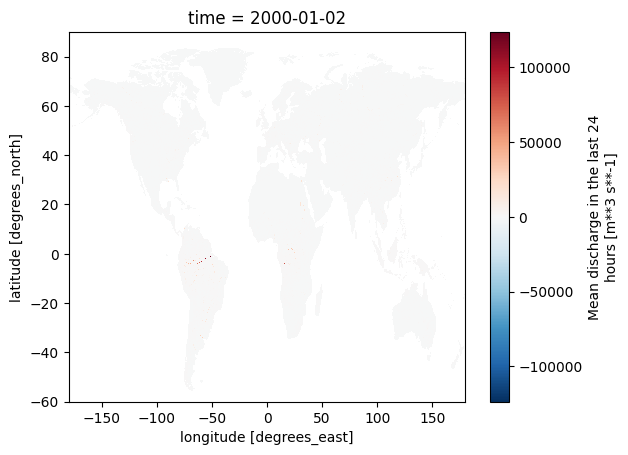

In [16]:
glofas.dis24[0,:].plot()

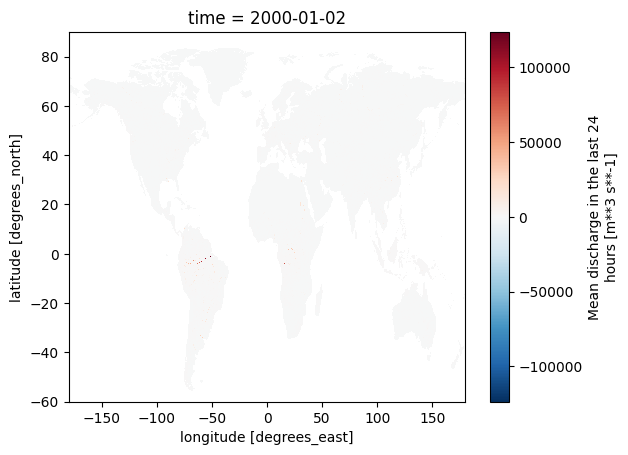

In [17]:
# Flip the lat dimension and its coordinates
glofas_flipped = glofas.dis24.isel(lat=slice(None, None, -1))
glofas_flipped[0,:].plot()

In [18]:
glofas_flipped

<xarray.DataArray 'dis24' (time: 7671, lat: 1500, lon: 3600)>
[41423400000 values with dtype=float32]
Coordinates:
  * lon      (lon) float32 -179.9 -179.9 -179.8 -179.6 ... 179.8 179.9 179.9
  * lat      (lat) float32 -59.95 -59.85 -59.75 -59.65 ... 89.75 89.85 89.95
  * time     (time) datetime64[ns] 2000-01-02 2000-01-03 ... 2021-01-01
Attributes:
    units:      m**3 s**-1
    long_name:  Mean discharge in the last 24 hours

In [19]:
# fix longitudes and latitudes
longitudes = np.arange(-179.95, 180, 0.1)
latitudes = np.arange(-59.95, 90, 0.1)

# Create an xarray DataArray
longitude_grid = xarray.DataArray(longitudes, dims=["lon"], coords={"lon": longitudes})
latitude_grid = xarray.DataArray(latitudes, dims=["lat"], coords={"lat": latitudes})

glofas_flipped["lat"] = latitude_grid
glofas_flipped["lon"] = longitude_grid

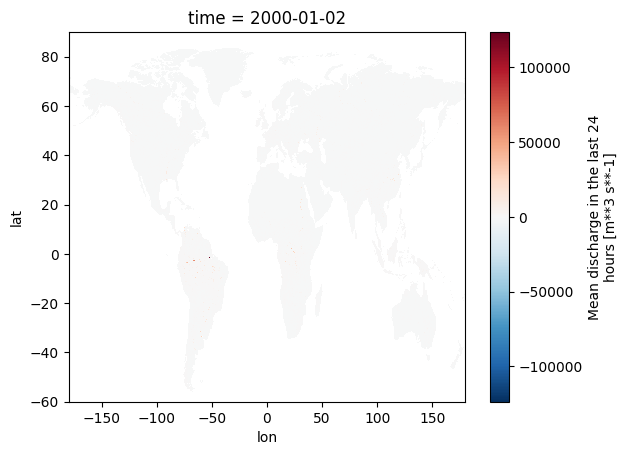

In [20]:
glofas_flipped[0,:].plot()

In [21]:
# subset
glofas_little_nwa = glofas_flipped.sel(**glofas_subset).isel(time=slice(0,1000))
glofas_little_nwa

<xarray.DataArray 'dis24' (time: 1000, lat: 155, lon: 193)>
[29915000 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 2000-01-02 2000-01-03 ... 2002-09-27
  * lat      (lat) float64 14.65 14.75 14.85 14.95 ... 29.75 29.85 29.95 30.05
  * lon      (lon) float64 -98.95 -98.85 -98.75 -98.65 ... -79.95 -79.85 -79.75
Attributes:
    units:      m**3 s**-1
    long_name:  Mean discharge in the last 24 hours

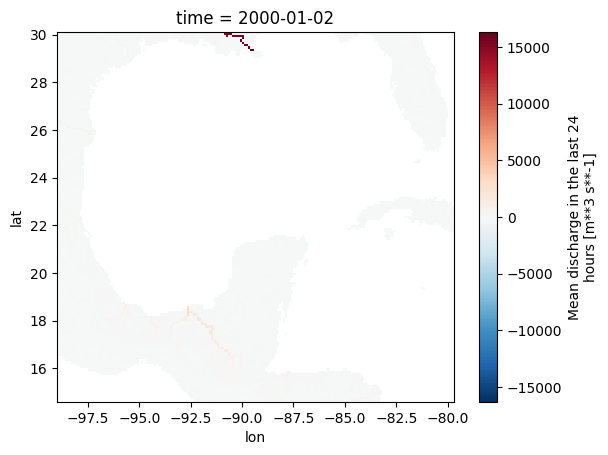

In [22]:
glofas_little_nwa[0,:].plot()

In [23]:
glofas_latb = np.arange(glofas_little_nwa['lat'][0]-.05, glofas_little_nwa['lat'][-1]+.051, .1)
glofas_lonb = np.arange(glofas_little_nwa['lon'][0]-.05, glofas_little_nwa['lon'][-1]+.051, .1)

In [24]:
lon = hgrid.x[1::2, 1::2]
lonb = hgrid.x[::2, ::2]
lat = hgrid.y[1::2, 1::2]
latb = hgrid.y[::2, ::2]
# From Alistair
area = (hgrid.area[::2, ::2] + hgrid.area[1::2, 1::2]) + (hgrid.area[1::2, ::2] + hgrid.area[::2, 1::2])

In [25]:
# Convert m3/s to kg/m2/s
# Borrowed from https://xgcm.readthedocs.io/en/latest/xgcm-examples/05_autogenerate.html
distance_1deg_equator = 111000.0
dlon = dlat = 0.1  # GloFAS grid spacing
deg2rad = xarray.apply_ufunc(wrapper_deg2rad, glofas_little_nwa.lat)
cos = xarray.apply_ufunc(wrapper_cos, deg2rad)
dx = dlon * cos * distance_1deg_equator
dy = ((glofas_little_nwa.lon * 0) + 1) * dlat * distance_1deg_equator
glofas_area = dx * dy
glofas_rof = glofas_little_nwa * 1000.0 / glofas_area

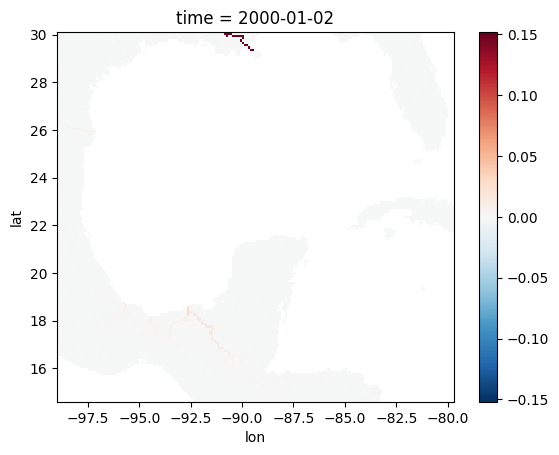

In [26]:
glofas_rof[0,:].plot()

In [28]:
%%time
# Conservatively interpolate runoff onto MOM grid
glofas_to_mom_con = xesmf.Regridder(
    {'lon': glofas_little_nwa.lon, 'lat': glofas_little_nwa.lat, 'lon_b': glofas_lonb, 'lat_b': glofas_latb},
    {'lat': lat, 'lon': lon, 'lat_b': latb, 'lon_b': lonb},
    method='bilinear',
    periodic=False,
    reuse_weights=False
)

CPU times: user 237 ms, sys: 101 ms, total: 338 ms
Wall time: 1.46 s


In [29]:
%%time
# Interpolate only from GloFAS points that are river end points.
glofas_regridded = glofas_to_mom_con(glofas_rof.where(points > 0).fillna(0.0))

CPU times: user 623 ms, sys: 150 ms, total: 774 ms
Wall time: 3.09 s


In [30]:
%%time
glofas_regridded = glofas_regridded.rename({'nyp': 'ny', 'nxp': 'nx'}).values

CPU times: user 206 µs, sys: 56 µs, total: 262 µs
Wall time: 266 µs


In [31]:
# Flatten mask and coordinates to 1D
flat_mask = coast_mask.ravel().astype('bool')
coast_lon = lon.values.ravel()[flat_mask]
coast_lat = lat.values.ravel()[flat_mask]
mom_id = np.arange(np.prod(coast_mask.shape))

In [32]:
# Use xesmf to find the index of the nearest coastal cell
# for every grid cell in the MOM domain
coast_to_mom = xesmf.Regridder(
    {'lat': coast_lat, 'lon': coast_lon},
    {'lat': lat, 'lon': lon},
    method='nearest_s2d',
    locstream_in=True,
    reuse_weights=False
)

In [33]:
print("finished coast 2 mom regridding")
coast_id = mom_id[flat_mask]
nearest_coast = coast_to_mom(coast_id).ravel()

finished coast 2 mom regridding


In [34]:
# Raw runoff on MOM grid, reshaped to 2D (time, grid_id)
raw = glofas_regridded.reshape([glofas_regridded.shape[0], -1])

In [35]:
# Zero array that will be filled with runoff at coastal cells
filled = np.zeros_like(raw)

In [36]:
# Loop over each coastal cell and fill the result array
# with the sum of runoff for every grid cell that
# has this coastal cell as its closest coastal cell
for i in coast_id:
    filled[:, i] = raw[:, nearest_coast == i].sum(axis=1)

In [37]:
# Reshape back to 3D
filled_reshape = filled.reshape(glofas_regridded.shape)

In [39]:
# For NWA only: Mississippi River adjustment.
# Adjust to be approximately the same as the USGS station at Belle Chasse, LA
# and relocate closer to the end of the delta.
#ms_total_kg = filled_reshape[:, 285:295, 189:197] 
#ms_total = (ms_total_kg * np.broadcast_to(area[285:295, 189:197], ms_total_kg.shape)).sum(axis=(1, 2)) * 0.63 
#filled_reshape[:, 285:295, 189:197] = 0.0
#new_ms_coords = [(285, 188), (282, 191), (284, 195)]
#for c in new_ms_coords:
    #y, x = c
    #filled_reshape[:, y, x] = (1 / len(new_ms_coords)) * ms_total / float(area[y, x])

# For NWA only: add the lower Atchafalaya River based on 
# a linear regression using Belle Chasse, LA. 
# 1. Convert back to m3 / s
#ms_total_cms = ms_total / 1000.0
# 2. Estimate from regression. 
#estimate = 0.25398171869266334 * ms_total_cms - 321.07060528972397
# Keep the estimate >= 0.
#estimate = np.clip(estimate, 0, None)
# 3. Convert back to kg / m2 / s
#estimate_kg = estimate * 1000.0 / float(area[310, 177])
# 4. Add in place of existing Atchafalaya River in GloFAS. 
#filled_reshape[:, 310, 177] += estimate_kg

# Convert to xarray
ds = xarray.Dataset({
    'runoff': (['time', 'y', 'x'], filled_reshape),
    'area': (['y', 'x'], area.data),
    'lat': (['y', 'x'], lat.data),
    'lon': (['y', 'x'], lon.data)
    },
    coords={'time': glofas_rof['time'].data, 'y': np.arange(filled_reshape.shape[1]),
            'x': np.arange(filled_reshape.shape[2])}
)

In [40]:
# Drop '_FillValue' from all variables when writing out
all_vars = list(ds.data_vars.keys()) + list(ds.coords.keys())
encodings = {v: {'_FillValue': None} for v in all_vars}

# Make sure time has the right units and datatype
# otherwise it will become an int and MOM will fail. 
encodings['time'].update({
    'units': 'days since 1950-01-01',
    'dtype': float, 
    'calendar': 'gregorian'
})

ds['time'].attrs = {'cartesian_axis': 'T'}
ds['x'].attrs = {'cartesian_axis': 'X'}
ds['y'].attrs = {'cartesian_axis': 'Y'}
ds['lat'].attrs = {'units': 'degrees_north'}
ds['lon'].attrs = {'units': 'degrees_east'}
ds['runoff'].attrs = {'units': 'kg m-2 s-1'}

print(ds)

<xarray.Dataset>
Dimensions:  (time: 1000, y: 26, x: 29)
Coordinates:
  * time     (time) datetime64[ns] 2000-01-02 2000-01-03 ... 2002-09-27
  * y        (y) int64 0 1 2 3 4 5 6 7 8 9 10 ... 16 17 18 19 20 21 22 23 24 25
  * x        (x) int64 0 1 2 3 4 5 6 7 8 9 10 ... 19 20 21 22 23 24 25 26 27 28
Data variables:
    runoff   (time, y, x) float64 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    area     (y, x) float64 4.19e+09 4.19e+09 4.19e+09 ... 4.035e+09 4.037e+09
    lat      (y, x) float64 14.88 14.88 14.88 14.88 ... 29.78 29.78 29.78 29.78
    lon      (y, x) float64 -98.67 -98.0 -97.33 -96.67 ... -81.34 -80.67 -80.01


### Convert arrays to Dask

In [42]:
import dask
import dask_jobqueue
import distributed

ModuleNotFoundError: No module named 'dask_jobqueue'

In [38]:
# Set your username here:
username = "gmarques"

if "client" in locals():
    client.close()
    del client
if "cluster" in locals():
    cluster.close()

cluster = dask_jobqueue.PBSCluster(
    cores=12,  # The number of cores you want
    memory="8GB",  # Amount of memory
    processes=1,  # How many processes
    queue="casper",  # The type of queue to utilize (/glade/u/apps/dav/opt/usr/bin/execcasper)
    log_directory=f"/glade/derecho/scratch/{username}/dask/",  # Use your local directory
    resource_spec="select=1:ncpus=1:mem=8GB",  # Specify resources
    project="CESM0023",   # Input your project ID here
    walltime="04:00:00",  # Amount of wall time
)
# cluster.adapt(maximum_jobs=24, minimum_jobs=2) # If you want to force everything to be quicker, increase the number of minimum jobs, 
# # but sometimes then it will take a while until you get them assigned, so it's a trade-off
cluster.scale(12) # I changed this because currently dask is flaky, this might have to be adjusted during the tutorial
client = distributed.Client(cluster)
client

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/gmarques/High-mem/proxy/8787/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/gmarques/High-mem/proxy/8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.101:44561,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/gmarques/High-mem/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [39]:
# Configure Dask to set the chunk size (e.g., 100MB)
dask.config.set({'array.chunk-size': '100MB'})

# Assuming 'ds' is your existing xarray.Dataset
# Convert the dataset to use Dask arrays with the configured chunk size
ds_dask = ds.chunk()

# Verify the conversion
print(ds_dask)

<xarray.Dataset> Size: 5GB
Dimensions:  (time: 1000, y: 780, x: 740)
Coordinates:
  * time     (time) datetime64[ns] 8kB 2000-01-02 2000-01-03 ... 2002-09-27
  * y        (y) int64 6kB 0 1 2 3 4 5 6 7 8 ... 772 773 774 775 776 777 778 779
  * x        (x) int64 6kB 0 1 2 3 4 5 6 7 8 ... 732 733 734 735 736 737 738 739
Data variables:
    runoff   (time, y, x) float64 5GB dask.array<chunksize=(1000, 780, 740), meta=np.ndarray>
    area     (y, x) float64 5MB dask.array<chunksize=(780, 740), meta=np.ndarray>
    lat      (y, x) float64 5MB dask.array<chunksize=(780, 740), meta=np.ndarray>
    lon      (y, x) float64 5MB dask.array<chunksize=(780, 740), meta=np.ndarray>


In [43]:
out_file

PosixPath('/glade/u/home/manishrv/documents/croc/dev/runoff/GloFAS_little_nwa.nc')

In [44]:
%%time
# Write out
ds.to_netcdf(
    out_file,
    unlimited_dims=['time'],
    format='NETCDF3_64BIT',
    encoding=encodings,
    engine='netcdf4'
)
ds.close()

CPU times: user 186 ms, sys: 115 ms, total: 302 ms
Wall time: 1.21 s


In [54]:
ds

<xarray.Dataset>
Dimensions:  (time: 1000, y: 26, x: 29)
Coordinates:
  * time     (time) datetime64[ns] 2000-01-02 2000-01-03 ... 2002-09-27
  * y        (y) int64 0 1 2 3 4 5 6 7 8 9 10 ... 16 17 18 19 20 21 22 23 24 25
  * x        (x) int64 0 1 2 3 4 5 6 7 8 9 10 ... 19 20 21 22 23 24 25 26 27 28
Data variables:
    runoff   (time, y, x) float64 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    area     (y, x) float64 4.19e+09 4.19e+09 4.19e+09 ... 4.035e+09 4.037e+09
    lat      (y, x) float64 14.88 14.88 14.88 14.88 ... 29.78 29.78 29.78 29.78
    lon      (y, x) float64 -98.67 -98.0 -97.33 -96.67 ... -81.34 -80.67 -80.01